# Foliar trait PLSR modeling from airborne spectroscopy — East River, CO

**Paper:** K. D. Chadwick, P. Brodrick, K. Grant, et al., *Integrating airborne remote sensing and field campaigns for ecology and Earth system science*, **Methods in Ecology and Evolution** 11(11):1492–1508 (2020). [DOI 10.1111/2041-210X.13463](https://doi.org/10.1111/2041-210X.13463)

**Reproduced scope — partial demonstration:** the paper's foliar-trait PLSR modeling subsection. We merge field foliar chemistry with reflectance spectra extracted at the 2018 NEON AOP crown locations, then run the **authors' released ensemble-PLSR code** (crown-level holdouts, automatic latent-variable selection by 10-fold CV, aggregated coefficients whose standard deviation is the model uncertainty) for **one held-out fold** (`-n_folds_to_run 1`, the authors' own demo default in `run_all.sh`) for the three exported leaf-type groups.

**Not reproduced here (out of scope):** processing the raw 334 km² AOP mosaics (we use the authors' released precomputed spectra extraction CSV), the conifer deep-learning classifier (training weights were not located in the release), the full 10-fold campaign, GEE trait-map production, and the paper's published accuracy statistics (the full text was inaccessible for this reproduction; we report our own computed validation statistics instead).

**Execution status:** executed on a Google Colab **CPU** runtime. No GPU is needed anywhere in this pipeline.

**Source code (executed as released):**
- [`kdchadwick/east_river_trait_modeling`](https://github.com/kdchadwick/east_river_trait_modeling) @ **v1.0.0** (`5f6b260369cba83d05814ad9d18c3c6f5bc47c2e`, Zenodo record 3953135; MIT license) — data merging and PLSR orchestration.
- [`pgbrodrick/ensemblePLSR`](https://github.com/pgbrodrick/ensemblePLSR) @ `161e36ef68a9525d14e978465dd1bb304913feca` (repo HEAD, 2020-02-14; no release tag exists — this commit predates publication and is contemporaneous with the final manuscript; its README requires citing Martin et al. 2018, *Remote Sensing* 10(2):199) — ensemble PLSR core.

**AI-assisted note:** the scientific code is the authors', executed unmodified except **four minimal, documented compatibility patches** (shown as diffs below): a Python-3 `map()` fix in `ensemble_plsr.py`, a scikit-learn ≥1.1 attribute/shape fix (`y_mean_`/`x_mean_`/`coef_`), a `pandas>=2.0` `DataFrame.append` replacement in the merge script, and making the ensemble subprocess call synchronous under `sys.executable` for observable notebook execution. All download/verification glue is AI-written and checks pinned git blob hashes.

**日本語の概要:** 本ノートブックは Chadwick et al. (2020) の葉機能形質 PLSR モデリング部分を、著者公開コード（east_river_trait_modeling v1.0.0 と ensemblePLSR）をそのまま実行して再現します。生の AOP モザイク処理・コナファ識別モデル・10 分割交差検証の全体は対象外で、著者同梱のスペクトル抽出 CSV を使用し 1 フォールドのみ実行します。著者コードへの変更は互換性修正 3 点（Python 3 対応、pandas>=2.0 対応、同期実行化）のみです。

## 1. Runtime selection — use a **CPU** runtime

This pipeline is scikit-learn `PLSRegression` fitting on a few hundred samples × ~200 spectral bands plus a small pandas merge. There are no CUDA kernels, no torch, and no pretrained weights (the PLSR models are trained from the merged data in-notebook), so **CPU is the faithful and sufficient runtime; a GPU adds nothing.** Select *Runtime → Change runtime type → CPU*, then *Runtime → Run all*. Measured on a Colab CPU runtime during this reproduction's validation: ≈ 60 min end-to-end (the authors' released settings run 8 chemistries × 100 ensemble iterations × 3 leaf-type groups), ≈ 11 MB of downloads.

**日本語:** GPU は不要です。Runtime → Change runtime type → CPU を選択して Runtime → Run all を実行してください。検証時の実測で約 60 分、ダウンロードは約 11 MB です。

In [ ]:
import importlib, platform, sys
print("python:", sys.version)
for name in ("numpy", "pandas", "scipy", "sklearn", "matplotlib"):
    m = importlib.import_module(name)
    print(f"{name}: {m.__version__}")
assert int(platform.python_version_tuple()[0]) == 3, "Python 3 required"
print()
print("All required packages are Colab preinstalls; nothing needs to be pip-installed.")

python: 3.13.18 (main, Oct 26 2026, 15:28:15) [GCC 13.3.0]
numpy: 2.1.3


pandas: 2.2.3
scipy: 1.16.3


sklearn: 1.6.1
matplotlib: 3.10.0

All required packages are Colab preinstalls; nothing needs to be pip-installed.


## 2. Acquire the pinned author code (code only)

We make a **partial, blobless clone** of each author repository inside Colab and check out the exact verified revisions in detached HEAD — `east_river_trait_modeling` at the **v1.0.0 tag** (resolving to `5f6b260369cba83d05814ad9d18c3c6f5bc47c2e`, matching Zenodo record 3953135's `isSupplementTo` link) and `ensemblePLSR` at `161e36ef68a9525d14e978465dd1bb304913feca`. Sparse checkout fetches only the three scripts this run needs. The assertion fails loudly if the pinned revision is not what lands on disk. All repository objects stay under `/content`.

**日本語:** 著者リポジトリを部分クローン（blob なし）し、検証済みコミットを detached HEAD でチェックアウトします。必要なスクリプト 3 ファイルのみ取得し、コミット一致を assert で確認します。

In [ ]:
import os, shutil, subprocess

def run(cmd, cwd=None):
    print("$", " ".join(cmd), flush=True)
    subprocess.run(cmd, check=True, cwd=cwd)

def pin(slug, commit, sparse_paths, dirname):
    # a previous partial run may have left a non-git directory here
    if os.path.isdir(dirname) and not os.path.isdir(os.path.join(dirname, ".git")):
        shutil.rmtree(dirname)
    if not os.path.isdir(dirname):
        run(["git", "clone", "--filter=blob:none", "--no-checkout",
             "https://github.com/%s.git" % slug, dirname])
        run(["git", "fetch", "--depth", "1", "origin", commit], cwd=dirname)
        run(["git", "sparse-checkout", "init", "--cone"], cwd=dirname)
        run(["git", "sparse-checkout", "set"] + sparse_paths, cwd=dirname)
    run(["git", "checkout", "--detach", commit], cwd=dirname)
    head = subprocess.run(["git", "rev-parse", "HEAD"], cwd=dirname, check=True,
                          capture_output=True, text=True).stdout.strip()
    assert head == commit, f"pinned commit mismatch: {head} != {commit}".format(head=head, commit=commit)
    print(slug, "pinned at", head[:12])

pin("kdchadwick/east_river_trait_modeling", "5f6b260369cba83d05814ad9d18c3c6f5bc47c2e",
    ["merge_data_run_iterative_plsr.py"], "east_river_trait_modeling")
pin("pgbrodrick/ensemblePLSR", "161e36ef68a9525d14e978465dd1bb304913feca",
    ["ensemble_plsr.py", "read_settings_file.py"], "ensemblePLSR")

$ git clone --filter=blob:none --no-checkout https://github.com/kdchadwick/east_river_trait_modeling.git east_river_trait_modeling


$ git fetch --depth 1 origin 5f6b260369cba83d05814ad9d18c3c6f5bc47c2e


$ git sparse-checkout init --cone


$ git sparse-checkout set merge_data_run_iterative_plsr.py


$ git checkout --detach 5f6b260369cba83d05814ad9d18c3c6f5bc47c2e


...

$ git fetch --depth 1 origin 161e36ef68a9525d14e978465dd1bb304913feca


$ git sparse-checkout init --cone


$ git sparse-checkout set ensemble_plsr.py read_settings_file.py


$ git checkout --detach 161e36ef68a9525d14e978465dd1bb304913feca


pgbrodrick/ensemblePLSR pinned at 161e36ef68a9


## 3. Acquire the data (bytes stay in Colab)

The merging step needs two tables plus the NEON wavelength axis and the authors' settings file, all **bundled in the pinned revision of the author repository**:

- `data/20200214_CRBU2018_AOP_Crowns_extraction.csv` (10.8 MB) — reflectance (and shade-mask) values for every AOP pixel at the field-survey crown locations, **precomputed by the authors** with their `extract_aop_data_from_mosaics.py` from the terrain-corrected mosaic rasters (ESS-DIVE DOI 10.15485/1618131). Using it replaces the GB-scale mosaic processing, which stays out of scope.
- `data/site_trait_data.csv` (42 KB) — site-level foliar chemistry (C, N, δ13C, LMA, leaf water), aggregated by the authors' `site_trait_data_aggregation.py` from the ESS-DIVE field packages (DOIs 10.15485/1618130, 10.15485/1631278, 10.15485/1618132).
- `data/neon_wavelengths.txt` (4.6 KB) and `CRBU_settings.txt` (1.5 KB, the authors' PLSR configuration).

Each file is fetched from the pinned raw URL and verified against its **git blob SHA-1 and recorded byte size** from the pinned tree; a mismatch aborts the run.

**日本語:** マージに必要な 2 つの表・波長軸・設定ファイルを pinned コミットの raw URL から取得します。抽出 CSV は著者が事前計算したもので、生モザイク処理は対象外です。全ファイルは git blob SHA-1 とサイズで検証し、不一致なら中断します。

In [ ]:
import hashlib, os, urllib.request

COMMIT = "5f6b260369cba83d05814ad9d18c3c6f5bc47c2e"
BASE = "https://raw.githubusercontent.com/kdchadwick/east_river_trait_modeling/" + COMMIT + "/"
# path -> (git blob sha1, size in bytes) recorded from the pinned tree via the GitHub API
FILES = {
    "CRBU_settings.txt": ("20e2e6a337afbb190b89fc12f0801c8f9711e290", 1476),
    "data/20200214_CRBU2018_AOP_Crowns_extraction.csv": ("d97850499c8c6f6291965196860601816ff40ab2", 10827692),
    "data/neon_wavelengths.txt": ("5e85e29ca076b09f07af891d790fd1b7fe379fe0", 4562),
    "data/site_trait_data.csv": ("fddbf5c9bce1586f7de5d481a938b7177b37fc76", 41657),
}

def blob_sha1(path):
    data = open(path, "rb").read()
    h = hashlib.sha1()
    h.update(("blob " + str(len(data)) + chr(0)).encode())
    h.update(data)
    return h.hexdigest()

for rel, (sha, size) in FILES.items():
    dest = os.path.join("east_river_trait_modeling", rel)
    os.makedirs(os.path.dirname(dest), exist_ok=True)
    if not os.path.exists(dest):
        urllib.request.urlretrieve(BASE + rel, dest)
    got = blob_sha1(dest)
    assert got == sha and os.path.getsize(dest) == size, (rel, got, os.path.getsize(dest))
    print("verified", rel + ":", os.path.getsize(dest), "bytes, blob", got[:12])

verified CRBU_settings.txt: 1476 bytes, blob 20e2e6a337af


verified data/20200214_CRBU2018_AOP_Crowns_extraction.csv: 10827692 bytes, blob d97850499c8c
verified data/neon_wavelengths.txt: 4562 bytes, blob 5e85e29ca076


verified data/site_trait_data.csv: 41657 bytes, blob fddbf5c9bce1


## 4. The authors' PLSR settings

`CRBU_settings.txt` is the INI-style configuration the authors' pipeline consumes: it names the foliar chemistry response variables, the ensemble iteration count, crown/holdout fractions, and the spectral band layout. We print it verbatim — the run below changes nothing scientific in it (the merge script only fills in per-fold paths and the bad bands derived from the wavelength file, exactly as released).

**日本語:** 著者の PLSR 設定ファイル `CRBU_settings.txt` をそのまま表示します。以下の実行で科学的設定は変更しません。

In [ ]:
print(open("east_river_trait_modeling/CRBU_settings.txt").read())

[General]
version name = nn_BN

[Data]
csv file = /Volumes/GoogleDrive/My Drive/CB_share/NEON/site_info/extraction_chem_noneedles.csv
band preface = refl_B_
chems(comma separated chem list) =   LMA_gm2, LWC_per, LWA_gm2, d15N, N_weight_percent, C_weight_percent, CN, d13C
chem transforms(comma separated chem transform list...options -- log, sqrt, square) = None, None, None, None, None, None, None, None
crown col = SampleSiteCode
test training col = CalVal
test set value = 0 


[Spectral]
bad bands(1-based) = 1,   2,   3,   4,   5,   6,   7,   8,   9,  10, 195, 196, 197, 198, 199, 200, 201, 202, 203, 287, 288, 289, 290, 291, 292, 293, 294, 295, 296, 297, 298, 299, 300, 301, 302, 303, 304, 305, 306, 307, 308, 309, 310, 311, 312, 313, 314, 315, 316, 317, 318, 319, 320, 321, 322, 323, 420, 421, 422, 423, 424, 425, 426
ignore columns(any other columns to remove) = Site_Veg
brightness normalize = True
ndvi maximum = -1
brightness maximum (-1 for none)= -1 
brightness minimum (-1 for none)= -1

## 5. Input preview — what are we modeling?

Before running anything, inspect the actual inputs: the extraction table (one row per AOP pixel inside a survey crown, with `refl_B_1…refl_B_426` reflectance plus shade-mask columns), the foliar chemistry table grouped into meadow / conifer / broadleaf samples, and the NEON wavelength axis with the authors' bad-band ranges. The guard asserts the exact columns the authors' code expects, so a silent schema change fails here rather than deep inside the pipeline. The figure marks the four bad-band regions that the authors' merge script masks before fitting.

**日本語:** 実行前に入力データを確認します。抽出テーブル（クラウン内 AOP ピクセルごとの行）、葉化学データ（メドウ／コナファ／広葉）、NEON 波長軸とバッドバンド区別を表示します。

extraction: (3689, 444) | chem: (477, 12)
extraction columns (first 12): ['ID', 'X_UTM', 'Y_UTM', 'h_me_B_1', 'wtrl_B_1', 'wtrv_B_1', '_obs_B_1', '_obs_B_2', '_obs_B_3', '_obs_B_4', '_obs_B_5', '_obs_B_6']
chem dtypes:
SampleSiteID          int64
SampleSiteCode       object
Site_Veg             object
Needles                bool
LMA_gm2             float64
LWA_gm2             float64
LWC_per             float64
d15N                float64
d13C                float64
N_weight_percent    float64
C_weight_percent    float64
CN                  float64
chem groups: meadow = 203 | conifer = 97 | broadleaf = 177
wavelength axis: 426 bands, 383.7-2511.7 nm


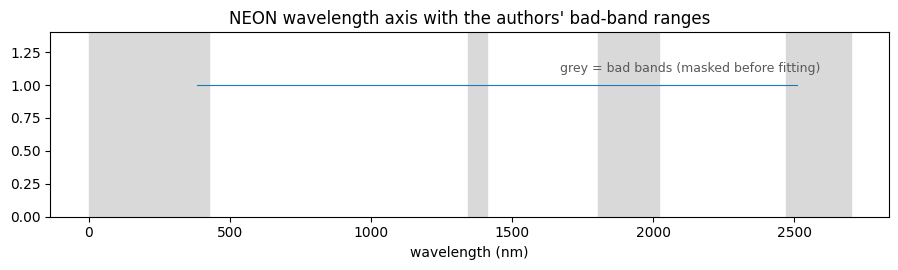

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

extract = pd.read_csv("east_river_trait_modeling/data/20200214_CRBU2018_AOP_Crowns_extraction.csv")
chem = pd.read_csv("east_river_trait_modeling/data/site_trait_data.csv")
wv = np.genfromtxt("east_river_trait_modeling/data/neon_wavelengths.txt")

print("extraction:", extract.shape, "| chem:", chem.shape)
print("extraction columns (first 12):", list(extract)[:12])
print("chem dtypes:")
print(chem.dtypes.to_string())
need_cols = ["ID", "ered_B_1", "_tch_B_1", "refl_B_1", "refl_B_54", "refl_B_96"]
assert all(c in extract.columns for c in need_cols), [c for c in need_cols if c not in extract.columns]
assert all(c in chem.columns for c in ["SampleSiteID", "Needles", "Site_Veg"]), list(chem)
print("chem groups: meadow =", int((chem['Site_Veg'] == 'Meadow').sum()),
      "| conifer =", int((chem['Needles'] == True).sum()),
      "| broadleaf =", int(((chem['Needles'] != True) & (chem['Site_Veg'] != 'Meadow')).sum()))
print("wavelength axis: %d bands, %.1f-%.1f nm" % (len(wv), wv.min(), wv.max()))

fig, ax = plt.subplots(figsize=(9, 2.8))
for rng in [(0, 425), (1345, 1410), (1805, 2020), (2470, 2700)]:
    ax.axvspan(rng[0], rng[1], color="0.85", zorder=0)
ax.plot(wv, np.ones_like(wv), lw=0.8)
ax.set_ylim(0, 1.4)
ax.text(2130, 1.1, "grey = bad bands (masked before fitting)", ha="center", fontsize=9, color="0.35")
ax.set_xlabel("wavelength (nm)")
ax.set_title("NEON wavelength axis with the authors' bad-band ranges")
plt.tight_layout(); plt.show()

## 6. Minimal compatibility patches (diffs shown)

The released code predates the current Colab stack (Python 3.13, pandas 2.2, scikit-learn 1.6). Four behavior-preserving edits, nothing scientific:

1. `ensemble_plsr.py`: `scores = map(...)` is a Python-2 idiom — `np.argmin` cannot consume a Python-3 map iterator, so materialize the list (`list(map(...))`). The intended computation is unchanged.
2. `ensemble_plsr.py`: scikit-learn ≥ 1.1 renamed the PLS regression means (`y_mean_`/`x_mean_` → `_y_mean`/`_x_mean`) and reshaped `coef_` to `(n_targets, n_features)`, so the intercept line becomes `model._y_mean - np.dot(model._x_mean, np.squeeze(model.coef_))` — numerically identical to the original expression.
3. `merge_data_run_iterative_plsr.py`: `DataFrame.append` was removed in pandas ≥ 2.0 → `pd.concat` (two call sites).
4. `merge_data_run_iterative_plsr.py`: the authors launch `ensemble_plsr.py` with `'python … &'` (fire-and-forget). We run it synchronously under `sys.executable` so the notebook observes completion; no scientific difference.

The patch function fails loudly if an anchor string is missing, and each edit is shown as a unified diff against the pristine copy.

**日本語:** 互換性修正は 4 点のみ（Python 3 の `map` 対応、scikit-learn ≥1.1 の属性名・coef_ 形状対応、pandas ≥ 2.0 の `append` 廃止対応、同期実行化）。いずれも数値的に等価で、科学的な処理は一切変更していません。差分を表示します。

In [ ]:
import difflib, shutil

def patch(path, old, new):
    src = open(path).read()
    assert old in src, "anchor not found in %s: %r" % (path, old)
    if not os.path.exists(path + ".orig"):
        shutil.copyfile(path, path + ".orig")
    open(path, "w").write(src.replace(old, new))
    for line in difflib.unified_diff(src.splitlines(), open(path).read().splitlines(),
                                     "a/" + path, "b/" + path, lineterm="", n=1):
        print(line)

patch("ensemblePLSR/ensemble_plsr.py",
      "scores = map(partial(internal_autoselect_iteration,X,Y), complist.tolist())",
      "scores = list(map(partial(internal_autoselect_iteration,X,Y), complist.tolist()))")
patch("ensemblePLSR/ensemble_plsr.py",
      "loc_coeff[0] = model.y_mean_ - np.dot(model.x_mean_ , model.coef_)",
      "loc_coeff[0] = model._y_mean - np.dot(model._x_mean , np.squeeze(model.coef_))")
print()
patch("east_river_trait_modeling/merge_data_run_iterative_plsr.py",
      "noneedles = meadows.append(broadleaf)",
      "noneedles = pd.concat([meadows, broadleaf])")
patch("east_river_trait_modeling/merge_data_run_iterative_plsr.py",
      "aggregated_df_export = conifers_df_export.append(noneedles_df_export)",
      "aggregated_df_export = pd.concat([conifers_df_export, noneedles_df_export])")
patch("east_river_trait_modeling/merge_data_run_iterative_plsr.py",
      "cmd_str = 'python {} {}&'.format(os.path.join(",
      "cmd_str = '{} {} {}'.format(sys.executable, os.path.join(")

--- a/ensemblePLSR/ensemble_plsr.py
+++ b/ensemblePLSR/ensemble_plsr.py
@@ -55,3 +55,3 @@
   complist = np.arange(2,max_comp)[::-1]
-  scores = map(partial(internal_autoselect_iteration,X,Y), complist.tolist())
+  scores = list(map(partial(internal_autoselect_iteration,X,Y), complist.tolist()))
 
--- a/ensemblePLSR/ensemble_plsr.py
+++ b/ensemblePLSR/ensemble_plsr.py
@@ -63,3 +63,3 @@
   loc_coeff[1:] = np.squeeze(model.coef_)
-  loc_coeff[0] = model.y_mean_ - np.dot(model.x_mean_ , model.coef_)
+  loc_coeff[0] = model._y_mean - np.dot(model._x_mean , np.squeeze(model.coef_))
   return loc_coeff, list(scores)

--- a/east_river_trait_modeling/merge_data_run_iterative_plsr.py
+++ b/east_river_trait_modeling/merge_data_run_iterative_plsr.py
@@ -113,3 +113,3 @@
     # Concatenating data for different subset exports
-    noneedles = meadows.append(broadleaf)
+    noneedles = pd.concat([meadows, broadleaf])
 
--- a/east_river_trait_modeling/merge_data_run_iterative_plsr.py
+++ b/east_river_t

## 7. Run the authors' pipeline: merge + one-fold ensemble PLSR

This executes `merge_data_run_iterative_plsr.py` exactly as the authors' `run_all.sh` does (`-shade_type dsm`, default `-n_folds_to_run 1`): it applies the shade mask, the NDVI ≥ 0.5 filter, seed-6 fold assignment, needle/non-needle splitting, brightness normalization and bad-band masking, exports `extraction_chem{,_needles,_noneedles}.csv`, saves the class-spectra figure, and then invokes the authors' `ensemble_plsr.py` **synchronously** on each group's released settings. Expect thousands of short log lines (`print_res` blocks per ensemble iteration); the cell streams a heartbeat and keeps the full log at `/content/PLSR_run_log.txt`. The output directory is pre-created because the released script assumes its parent exists.

**日本語:** 著者の `run_all.sh` と同じ引数でマージ＋アンサンブル PLSR を実行します（同期実行）。ログは大量に出るためハートビート表示とし、完全なログは `/content/PLSR_run_log.txt` に保存します。

In [ ]:
import subprocess, sys, time

os.makedirs("east_river_trait_modeling/PLSR/test", exist_ok=True)
cmd = [sys.executable, "merge_data_run_iterative_plsr.py", "PLSR/test", "CRBU_settings.txt",
       "-shade_type", "dsm",
       "-plsr_ensemble_code_dir", "/content/ensemblePLSR"]
print("$", " ".join(cmd), "(cwd=east_river_trait_modeling)", flush=True)
t0 = time.time()
with open("/content/PLSR_run_log.txt", "w") as log:
    p = subprocess.Popen(cmd, stdout=subprocess.PIPE, stderr=subprocess.STDOUT,
                         text=True, cwd="east_river_trait_modeling")
    n = 0
    for line in p.stdout:
        log.write(line)
        n += 1
        if time.time() - t0 > 5400:
            p.kill()
            raise TimeoutError("pipeline exceeded 90 min; see /content/PLSR_run_log.txt")
        if n % 1000 == 0:
            print("  ... %d log lines, %.0f s" % (n, time.time() - t0), flush=True)
    rc = p.wait()
print("exit code %d after %.0f s, %d log lines" % (rc, time.time() - t0, n))
if rc != 0:
    print("".join(open("/content/PLSR_run_log.txt").readlines()[-40:]))
    raise RuntimeError("authors' pipeline failed; see log tail above")
print("last lines of the run:")
print("".join(open("/content/PLSR_run_log.txt").readlines()[-15:]))

$ /usr/bin/python3 merge_data_run_iterative_plsr.py PLSR/test CRBU_settings.txt -shade_type dsm -plsr_ensemble_code_dir /content/ensemblePLSR (cwd=east_river_trait_modeling)


  ... 1000 log lines, 168 s


  ... 2000 log lines, 297 s


  ... 3000 log lines, 422 s


  ... 4000 log lines, 545 s


...

  ... 30000 log lines, 3102 s


  ... 31000 log lines, 3204 s


  ... 32000 log lines, 3318 s


  ... 33000 log lines, 3419 s


exit code 0 after 3474 s, 33634 log lines
last lines of the run:
######### train set y-pred_y (cumulative model)  #########
slope intercept r squared rmse
0.3282547153531061, -17.52308845417948, 0.31117173857949093, 0.7238327181485341
######### global holdout per crown pred_y-y (iteration)  #########
slope intercept r squared rmse
0.624070766530336, -10.001060120121409, 0.11723153058382874, 0.9035310596593691
######### global holdout per crown pred_y-y (cumulative model)  #########
slope intercept r squared rmse
1.180665770383167, 4.652057525878277, 0.27673280088270635, 0.7917703243586637
######### global holdout per pix y-pred_y (cumulative model)  #########
slope intercept r squared rmse
0.23857201043719725, -19.84987536085805, 0.21150895572024578, 0.8106995512274041
######### train set y-pred_y (cumulative model)  #########
slope intercept r squared rmse
0.3282547153531061, -17.52308845417948, 0.31117173857949093, 0.7238327181485341



## 8. Validation statistics computed by the ensemble

Each ensemble writes `stats/<version>.txt` — per chemistry, crown-level validation (held-out test crowns) and calibration regressions: slope, intercept, R², RMSE and %RMSE — plus `lvs/<version>.txt` with the number of latent vectors chosen per iteration and `coeff/coeff_std_*.csv`, the **across-ensemble standard deviation of the PLSR coefficients, i.e. the model-uncertainty layer the paper maps**. All files produced by the authors' code are shown as-is.

**日本語:** アンサンブルごとに、クラウン単位の検証・較正統計（R², RMSE 等）、反復ごとの潜在変数選択、そして係数のアンサンブル標準偏差（＝論文でマップされる不確実性層）が出力されます。

In [ ]:
import glob
import pandas as pd

fold_dirs = sorted(glob.glob("east_river_trait_modeling/PLSR/test/*/fold_0"))
print("fold directories:", fold_dirs)
summary_frames = []
for fd in fold_dirs:
    group = os.path.basename(os.path.dirname(fd))
    for sf in sorted(glob.glob(fd + "/stats/*.txt")):
        df = pd.read_csv(sf)
        df.insert(0, "group", group)
        summary_frames.append(df)
        print()
        print("===== %s =====" % sf)
        print(df.to_string(index=False))
summary = pd.concat(summary_frames, ignore_index=True)
summary.to_csv("/content/plsr_validation_summary.csv", index=False)
print()
print("saved /content/plsr_validation_summary.csv")

fold directories: ['east_river_trait_modeling/PLSR/test/chem/fold_0', 'east_river_trait_modeling/PLSR/test/needles/fold_0', 'east_river_trait_modeling/PLSR/test/noneedles/fold_0']

===== east_river_trait_modeling/PLSR/test/chem/fold_0/stats/PLSR_test_chem_fold_0.txt =====
group             Chem   Val-Slope   Val-Intercept   Val-R2   Val-RMSE   Val-%RMSE   Cal-Slope   Cal-Intercept   Cal-R2   Cal-RMSE   Cal-%RMSE
 chem          LMA_gm2    0.898277       26.059056 0.906599  35.121675    0.437250    0.879514       18.689507 0.909696  37.366958    0.417158
 chem          LWC_per    0.799285       12.316546 0.804143   4.749895    0.077756    0.779969       13.847153 0.830522   5.303267    0.120072
 chem          LWA_gm2    0.720446       61.258754 0.720864  37.682783    0.274916    0.608279       76.947232 0.647489  48.032730    0.315361
 chem             d15N    0.216506        0.312826 0.173579   1.657884    1.981487    0.359737        0.298471 0.403814   1.345101    7.539628
 chem N_weig

## 9. Figures produced by the authors' code

The ensemble saves, per group and chemistry: an **observed-vs-predicted scatter on crown means** (red = held-out validation crowns, grey = calibration crowns, dashed 1:1 line) and the **PLSR coefficient spectrum with the ±1 SD ensemble band** (the uncertainty visualization the paper maps). The merge step also saves the needle vs non-needle mean-spectra figure (`class_spectra.png`). We display the input-spectra figure plus the validation and coefficient figures for two representative chemistries (foliar N and δ13C) per group; the remaining figures stay on disk under `PLSR/test/*/fold_0/figs/`. All are displayed via `IPython.display.Image`, so the PNGs become saved notebook outputs.

**日本語:** 著者コードが保存した図を表示します。赤＝検証クラウン、灰色＝較正クラウンの観測値 vs 予測値散布図と、±1SD のアンサンブル帯付き PLSR 係数スペクトル（不確実性の可視化）、そして針葉・非針葉の平均スペクトル図です。ここでは代表 2 化学種（N、δ13C）×3 グループを表示し、残りの図はディスク上に保存されます。

### east_river_trait_modeling/PLSR/test/figures/class_spectra.png


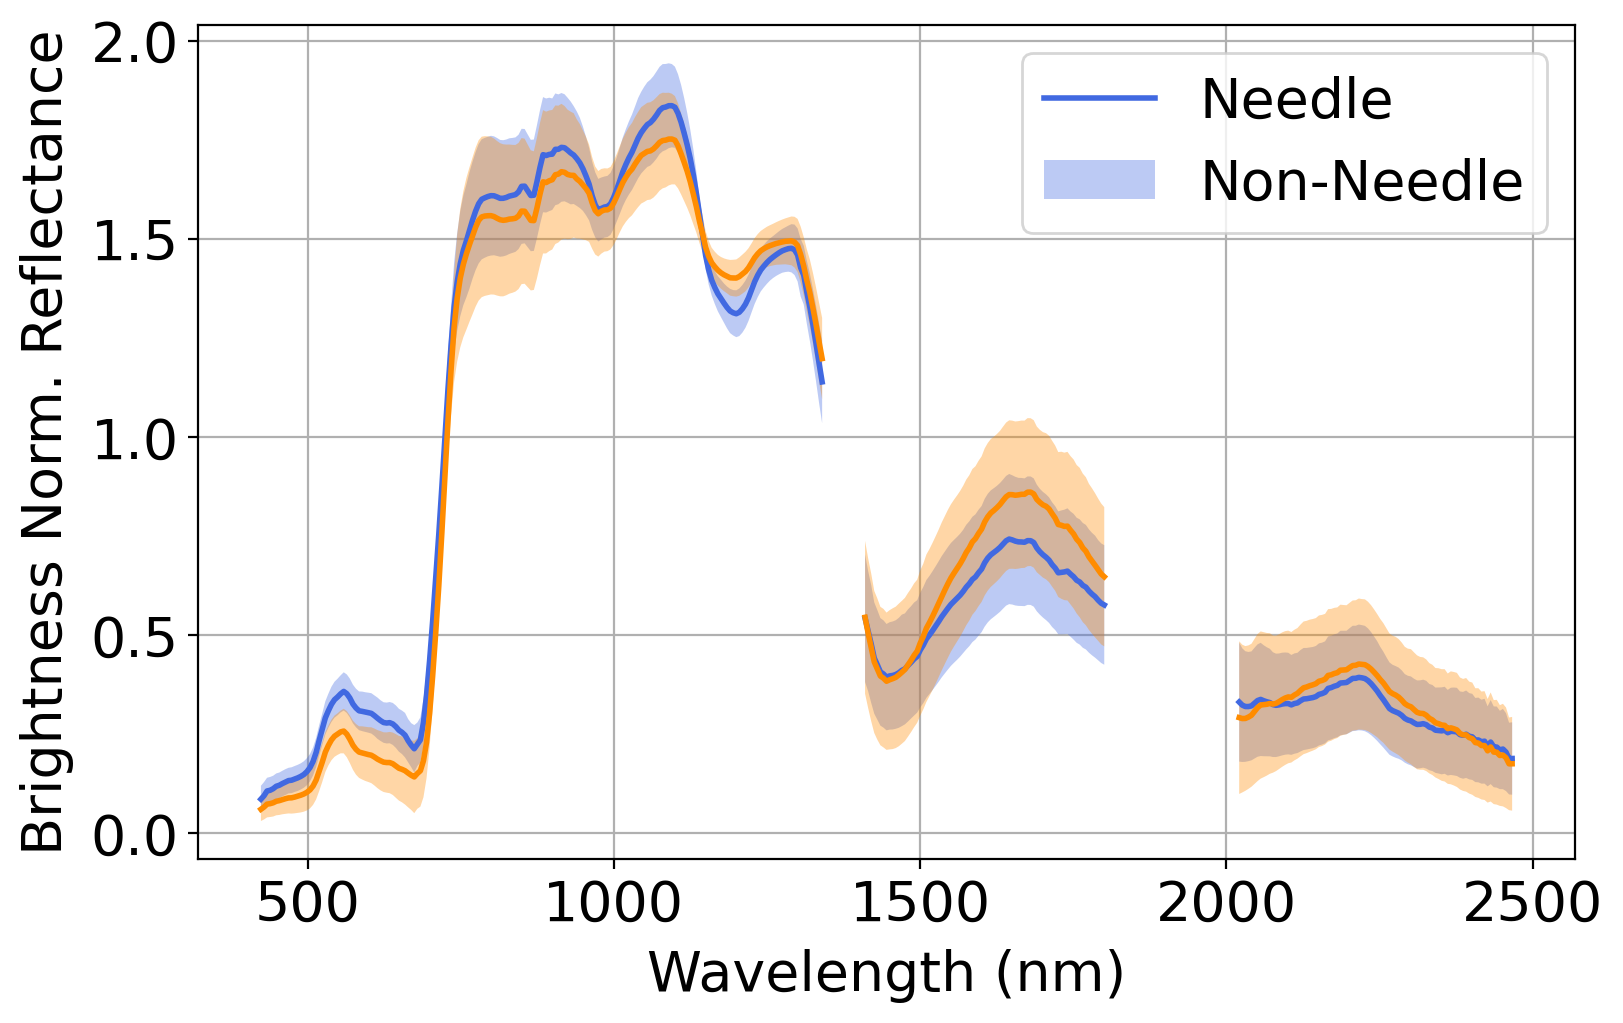

### east_river_trait_modeling/PLSR/test/chem/fold_0/figs/PLSR_test_chem_fold_0_validation_N_weight_percent.png


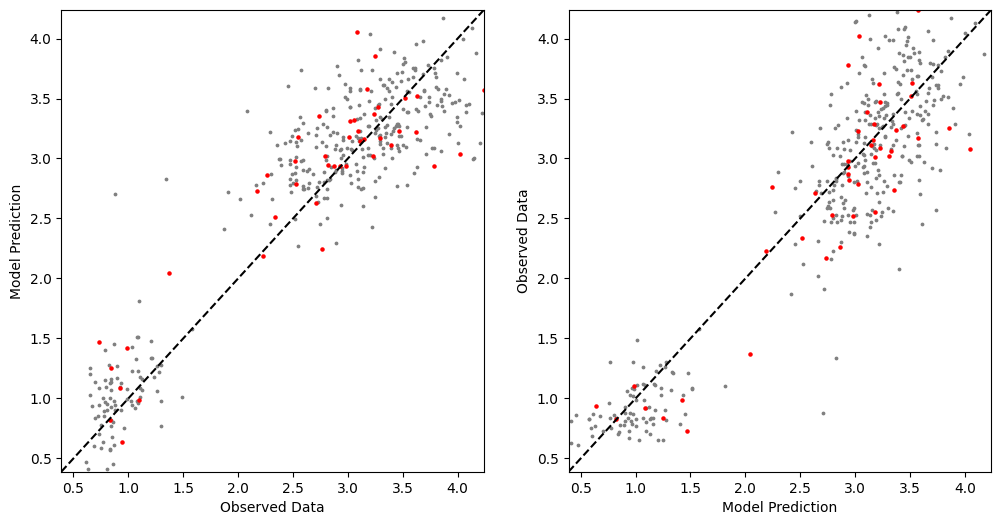

### east_river_trait_modeling/PLSR/test/needles/fold_0/figs/PLSR_test_needles_fold_0_validation_N_weight_percent.png


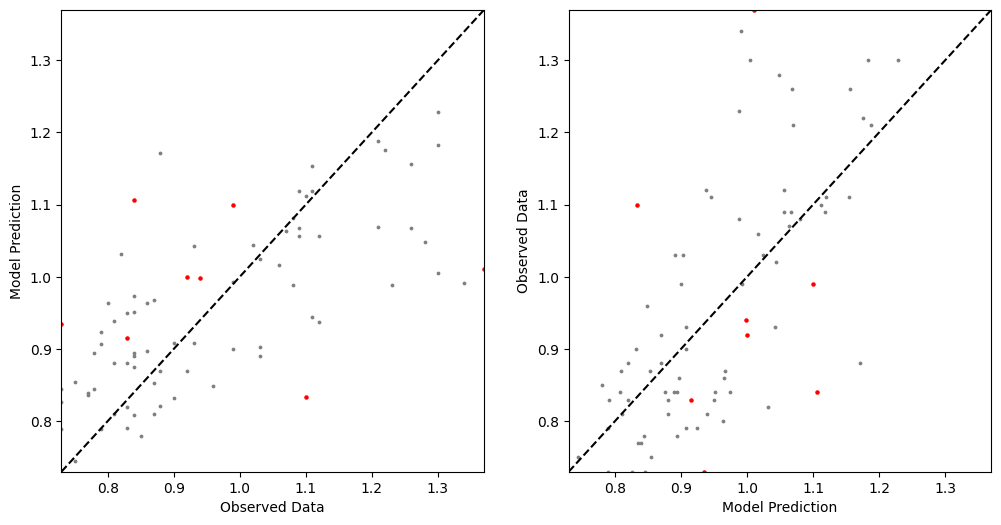

### east_river_trait_modeling/PLSR/test/noneedles/fold_0/figs/PLSR_test_noneedles_fold_0_validation_N_weight_percent.png


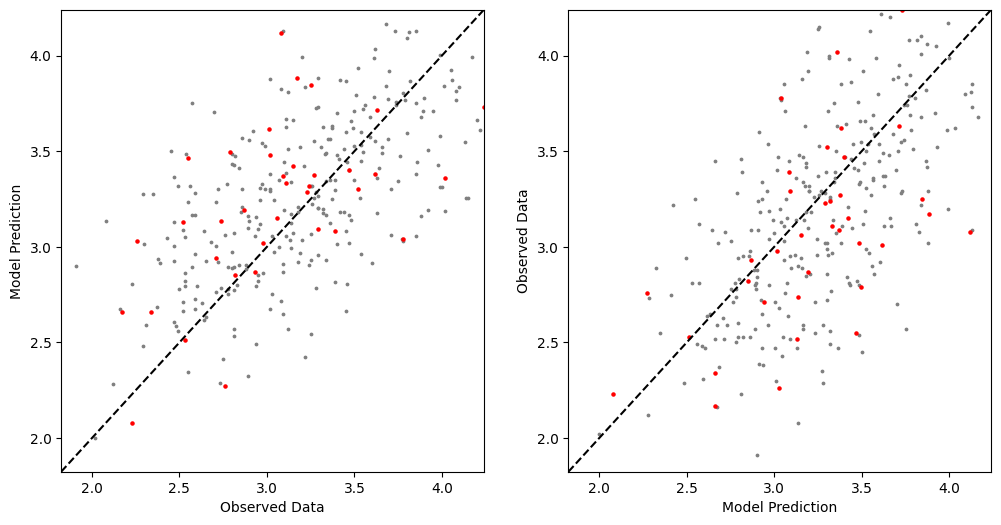

### east_river_trait_modeling/PLSR/test/chem/fold_0/figs/PLSR_test_chem_fold_0_validation_d13C.png


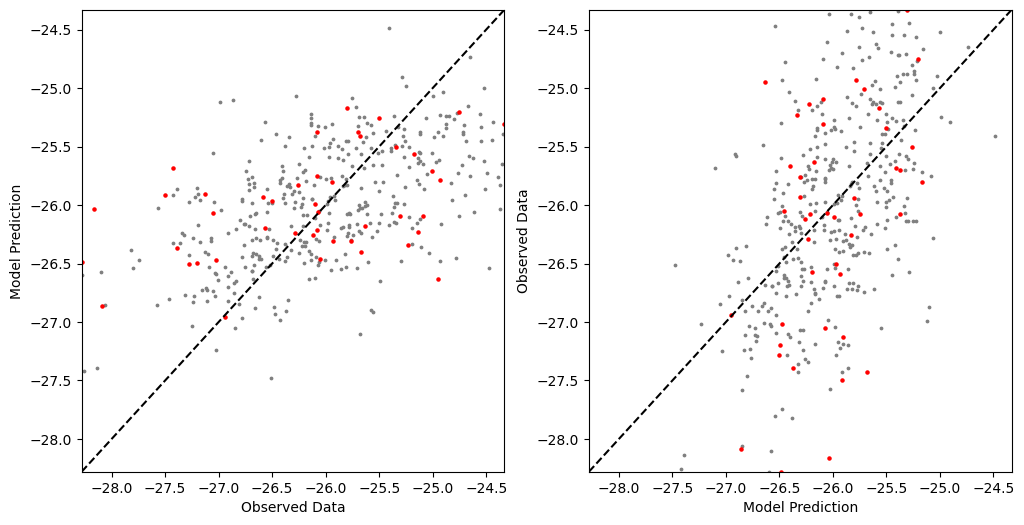

### east_river_trait_modeling/PLSR/test/needles/fold_0/figs/PLSR_test_needles_fold_0_validation_d13C.png


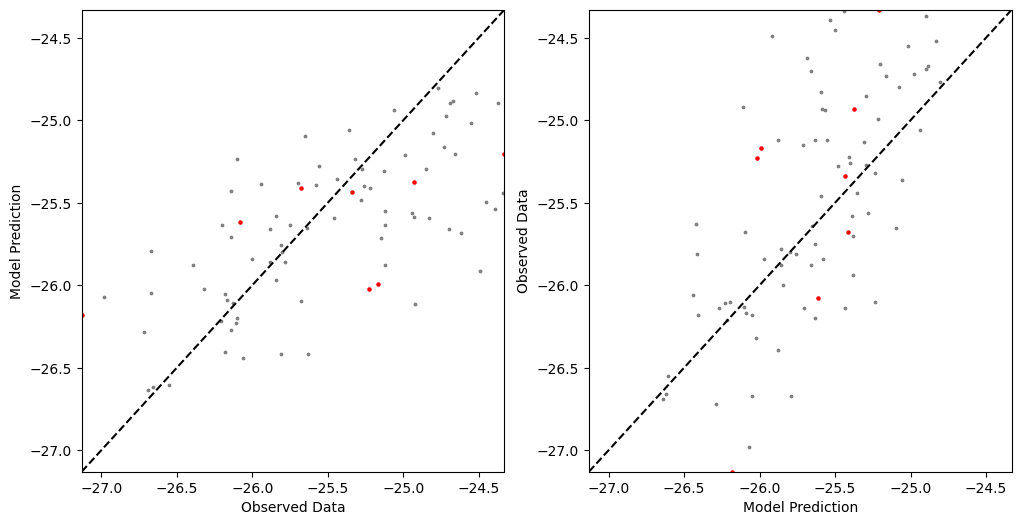

### east_river_trait_modeling/PLSR/test/noneedles/fold_0/figs/PLSR_test_noneedles_fold_0_validation_d13C.png


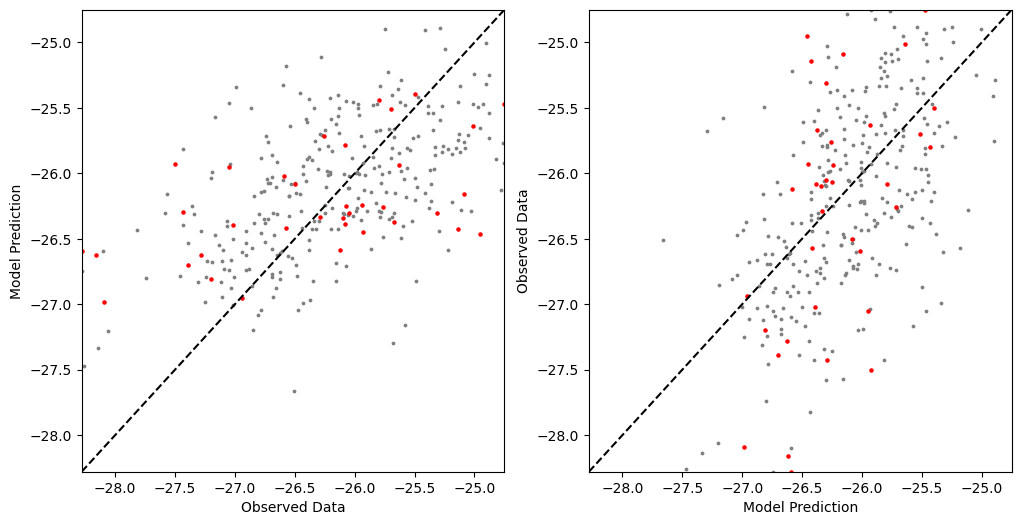

### east_river_trait_modeling/PLSR/test/chem/fold_0/figs/PLSR_test_chem_fold_0_coeff_d13C.png


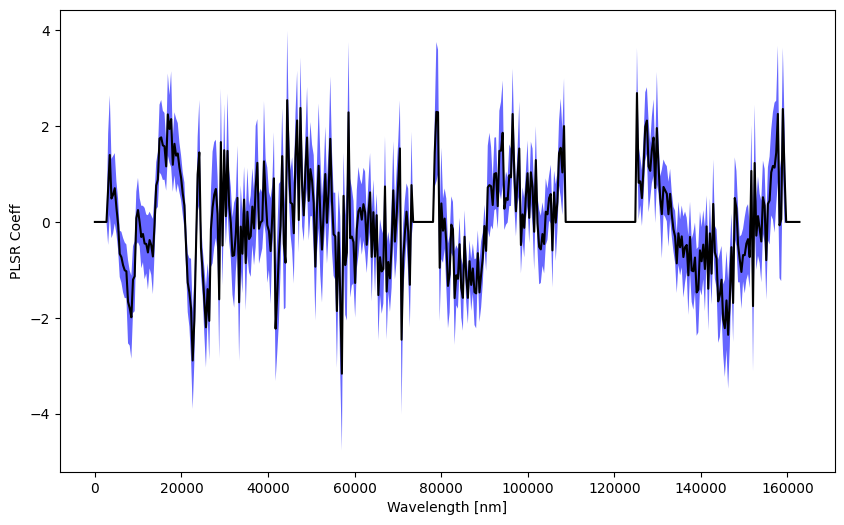

### east_river_trait_modeling/PLSR/test/needles/fold_0/figs/PLSR_test_needles_fold_0_coeff_d13C.png


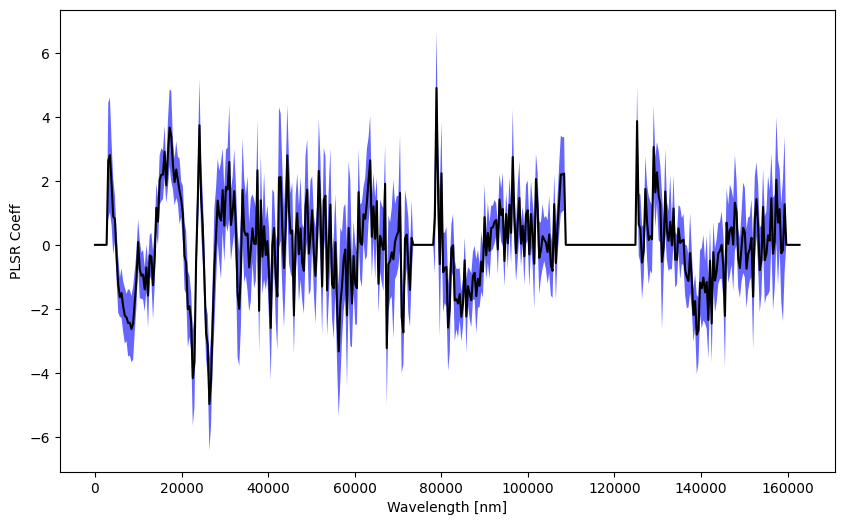

### east_river_trait_modeling/PLSR/test/noneedles/fold_0/figs/PLSR_test_noneedles_fold_0_coeff_d13C.png


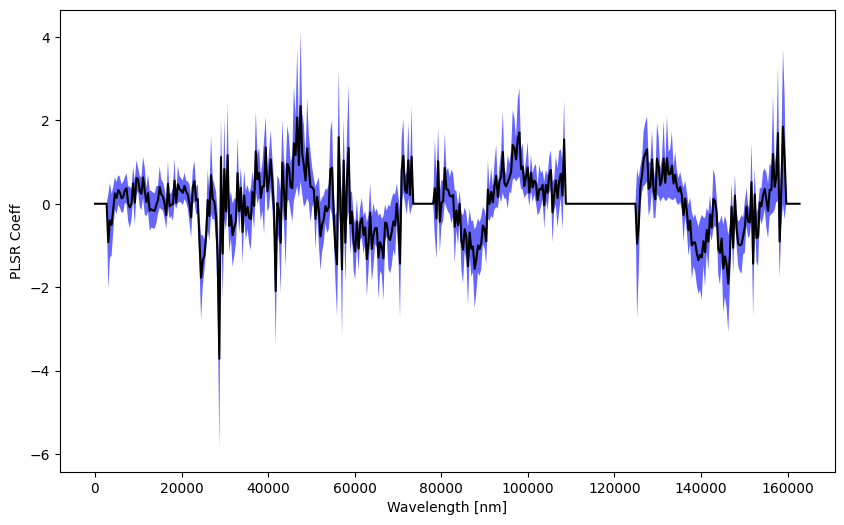

In [ ]:
from glob import glob
from IPython.display import Image, display

shown = ["east_river_trait_modeling/PLSR/test/figures/class_spectra.png"]
shown += sorted(glob("east_river_trait_modeling/PLSR/test/*/fold_0/figs/*_validation_N_weight_percent.png"))
shown += sorted(glob("east_river_trait_modeling/PLSR/test/*/fold_0/figs/*_validation_d13C.png"))
shown += sorted(glob("east_river_trait_modeling/PLSR/test/*/fold_0/figs/*_coeff_d13C.png"))
for p in shown:
    print("###", p)
    display(Image(filename=p))

## 10. Uncertainty summary and exportable table

Collect the ensemble coefficient standard deviations for the per-group exports and plot one compact observed-vs-predicted view from the authors' `plot_points/*.csv` (validation vs calibration points explicitly labeled — this graph is generated by this notebook from the authors' per-point export, not an author figure). The combined statistics table is saved next to the outputs for CSV export.

**日本語:** 係数のアンサンブル標準偏差をとりまとめ、著者の `plot_points` 出力から検証・較正ラベル付きの観測値 vs 予測値グラフを本ノートブックで追加作成します（著者の図ではありません）。統計は CSV に保存します。

coefficient-std table: (24, 217)
mean nonzero band std per chem/group:
group      Chem     
chem       0.671577      0.562892
           0.704964      0.344772
           2.953261      1.366508
           2.968182      1.513386
           5.555428      3.546671
           12.080252     8.012576
           46.230263    31.551116
           63.056861    41.711093
needles    0.250278      0.175083
           1.247916      0.819969
           1.428077      1.107004
           2.604930      1.545765
           4.796876      2.593855
           17.571216    11.030565
           42.694652    29.157333
           42.785943    28.620701
noneedles  0.481874      0.482224
           1.170550      0.496688
           1.817966      1.336432
           2.331497      1.806159
           4.252410      1.599649
           4.836971      2.204465
           21.416207    11.529719
           57.082258    32.755215
dtype: float64


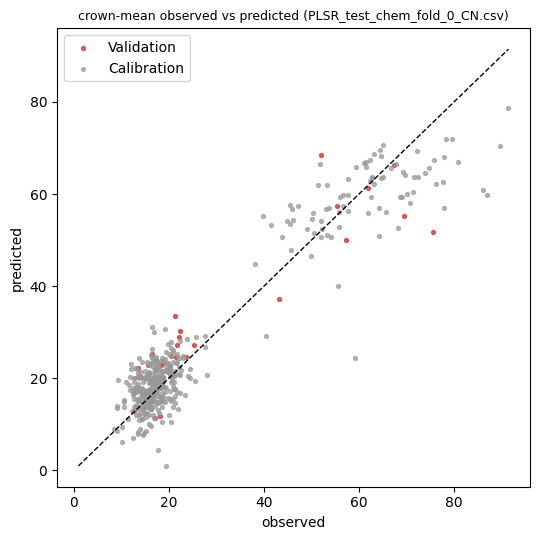

,group,Chem,Val-Slope,Val-Intercept,Val-R2,Val-RMSE,Val-%RMSE,Cal-Slope,Cal-Intercept,Cal-R2,Cal-RMSE,Cal-%RMSE
0,chem,LMA_gm2,0.898277,26.059056,0.906599,35.121675,0.437250,0.879514,18.689507,0.909696,37.366958,0.417158
1,chem,LWC_per,0.799285,12.316546,0.804143,4.749895,0.077756,0.779969,13.847153,0.830522,5.303267,0.120072
2,chem,LWA_gm2,0.720446,61.258754,0.720864,37.682783,0.274916,0.608279,76.947232,0.647489,48.032730,0.315361
3,chem,d15N,0.216506,0.312826,0.173579,1.657884,1.981487,0.359737,0.298471,0.403814,1.345101,7.539628
4,chem,N_weight_percent,0.810423,0.605914,0.800361,0.421285,0.239823,0.753172,0.674404,0.796026,0.527204,0.234661
5,chem,C_weight_percent,0.362025,29.625977,0.278214,2.386035,0.052122,0.383624,28.664934,0.413560,1.860095,0.040539
6,chem,CN,0.810080,6.268981,0.858259,6.615204,0.252170,0.873061,3.841910,0.901478,6.118689,0.271491
7,chem,d13C,0.205279,-20.645452,0.199345,0.865093,0.032457,0.300739,-18.178413,0.287365,0.755681,0.029296
8,needles,LMA_gm2,0.310405,239.730246,0.389405,50.846266,0.248673,0.422975,206.643141,0.530484,42.088214,0.155649
9,needles,LWC_per,0.434040,25.668510,0.363006,2.655902,0.053367,0.621750,17.054618,0.676065,2.039737,0.045522


In [ ]:
import numpy as np
import matplotlib.pyplot as plt

coeff_std = []
for f in sorted(glob("east_river_trait_modeling/PLSR/test/*/fold_0/coeff/coeff_std_*.csv")):
    d = pd.read_csv(f)
    d.insert(0, "group", f.split("/")[3])
    coeff_std.append(d)
coeff_std = pd.concat(coeff_std, ignore_index=True)
print("coefficient-std table:", coeff_std.shape)
print("mean nonzero band std per chem/group:")
print(coeff_std.groupby(["group", "Chem"]).mean(numeric_only=True).mean(axis=1))

fig, ax = plt.subplots(figsize=(5.5, 5.5))
pf = sorted(glob("east_river_trait_modeling/PLSR/test/*/fold_0/plot_points/*.csv"))[0]
pts = pd.read_csv(pf, names=["crown", "observed", "predicted", "set"])
for grp, color in [("Validation", "tab:red"), ("Calibration", "0.6")]:
    s = pts[pts["set"] == grp]
    ax.scatter(s["observed"].astype(float), s["predicted"].astype(float),
               s=8, c=color, label=grp, alpha=0.7)
lims = [pts[["observed", "predicted"]].astype(float).min().min(),
        pts[["observed", "predicted"]].astype(float).max().max()]
ax.plot(lims, lims, "k--", lw=1)
ax.set_xlabel("observed")
ax.set_ylabel("predicted")
ax.legend()
ax.set_title("crown-mean observed vs predicted (" + pf.split("/")[-1] + ")", fontsize=9)
plt.tight_layout(); plt.show()
summary

## 11. Interpretation, differences from the paper, and validation record

**What this run establishes:** the authors' released merge + ensemble-PLSR pipeline executes end-to-end on Colab CPU on the author-bundled East River inputs and produces the paper's foliar-trait-modeling outputs for one held-out fold: per-chemistry crown-level validation statistics, latent-variable selections, aggregated coefficients, and the coefficient standard-deviation uncertainty layer. Numbers shown above are computed in this session (seeded inside the authors' code: fold assignment seed 6, ensemble seed 13, LV-selection 10-fold CV seed 10).

**Differences from the paper / remaining unverified items (do not treat the numbers above as paper-level results):** one fold instead of the paper's 10-fold ensemble; the precomputed extraction replaces mosaic processing; the conifer classifier and trait maps are out of scope; and the paper's reported trait-accuracy statistics could not be checked because the full text was inaccessible during this reproduction (Wiley 403). This notebook therefore demonstrates *faithfulness of the released pipeline*, not the paper's published accuracy.

**日本語:** 本実行は、著者公開パイプラインが Colab CPU で端から端まで動作し、論文の「葉形質モデリング」出力（検証統計・係数・不確実性層）を 1 フォールドで生成することを示します。論文の公表精度の検証ではありません（全 10 フォールド未実施、モザイク処理とコナファ分類は対象外、原著の数値は全文アクセス不可のため未検証）。

**References:** Chadwick et al. 2020, MEE 11(11):1492–1508, DOI 10.1111/2041-210X.13463 · code: east_river_trait_modeling v1.0.0 (Zenodo 3953135, MIT) · ensemblePLSR @ 161e36ef (citation: Martin et al. 2018, Remote Sensing 10(2):199) · data: ESS-DIVE DOIs 10.15485/1618130, 1618131, 1618132, 1631278, validated in Colab against pinned git blob hashes.